In [1]:
import pandas as pd
import matplotlib.pylab as plt
import numpy as np
import seaborn as sns

In [2]:
df = pd.read_csv('../csv/appearances.csv')
print(df.dtypes)
df

appearance_id             object
game_id                    int64
player_id                  int64
player_club_id             int64
player_current_club_id     int64
date                      object
player_name               object
competition_id            object
yellow_cards               int64
red_cards                  int64
goals                      int64
assists                    int64
minutes_played             int64
dtype: object


,appearance_id,game_id,player_id,player_club_id,player_current_club_id,date,player_name,competition_id,yellow_cards,red_cards,goals,assists,minutes_played
0,2231978_38004,2231978,38004,853,235,2012-07-03,Aurélien Joachim,CLQ,0,0,2,0,90
1,2233748_79232,2233748,79232,8841,2698,2012-07-05,Ruslan Abyshov,ELQ,0,0,0,0,90
2,2234413_42792,2234413,42792,6251,465,2012-07-05,Sander Puri,ELQ,0,0,0,0,45
3,2234418_73333,2234418,73333,1274,6646,2012-07-05,Vegar Hedenstad,ELQ,0,0,0,0,90
4,2234421_122011,2234421,122011,195,3008,2012-07-05,Markus Henriksen,ELQ,0,0,0,1,90
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1507346,4172154_659813,4172154,659813,15,15,2023-11-30,Piero Hincapié,EL,0,0,0,0,90
1507347,4172154_696027,4172154,696027,15,15,2023-11-30,Ayman Aourir,EL,0,0,0,0,2
1507348,4172154_7161,4172154,7161,15,15,2023-11-30,Jonas Hofmann,EL,0,0,0,0,10
1507349,4172154_743395,4172154,743395,15,15,2023-11-30,Noah Mbamba,EL,0,0,0,0,45


# Data Exploration
The dataset contains 1507351 rows with 13 columns which are the following:
- `appearance_id` (object): The unique identifier for the appearance.
- `game_id` (int): The unique identifier for the game.
- `player_id` (int): The unique identifier for the player.
- `player_club_id` (int): The unique identifier for the player's club.
- `player_current_club_id` (int): The unique identifier for the player's current club.
- `date` (object): The date of the appearance.
- `player_name` (object): The name of the player.
- `competition_id` (object): The unique identifier for the competition.
- `yellow_cards` (int): The number of yellow cards the player received during the game.
- `red_cards` (int): The number of red cards the player received during the game.
- `goals` (int): The number of goals the player scored during the game.
- `assists` (int): The number of assists the player made during the game.
- `minutes_played` (int): The number of minutes the player played during the game.

In [3]:
#check for duplicated values
print("duplicated values in the df: ",df.duplicated().sum())

#change the date column to datetime
df['date'] = pd.to_datetime(df['date'])

#check for missing values
df.isnull().sum()

duplicated values in the df:  0


appearance_id               0
game_id                     0
player_id                   0
player_club_id              0
player_current_club_id      0
date                        0
player_name               324
competition_id              0
yellow_cards                0
red_cards                   0
goals                       0
assists                     0
minutes_played              0
dtype: int64

### Visualizing the missing data in the dataset
This section let us visualize the missing data in the dataset, we can see that the column `player_name` is the only one with missing values. This missing values are going to be replaced with the string 'unknown'.

In [4]:
# Access rows where player_name is 'unknown'
df.loc[df['player_name'].isnull(), 'player_name'] = 'unknown'
unknown = df.query('player_name == "unknown"').copy()  # Use .copy() to avoid the warning

print("unknown players: ", unknown.shape[0])
# Extract the year from the 'date' column using .loc to modify the 'unknown' DataFrame
unknown.loc[:, 'year'] = unknown['date'].dt.year

# Count the occurrences of 'unknown' players per year
unknown_count_per_year = unknown['year'].value_counts().sort_index()

# Display the result
unknown_count_per_year

Unknown players:  324


year
2014    171
2015    139
2016      9
2017      4
2018      1
Name: count, dtype: int64

### Handling Missing Values for Player Names


In this step, we handle missing values in the player_name column by replacing any NaN values with the string 'unknown'. After this, we query the DataFrame to identify players whose names were missing and replaced; there are 324 such players. We then try to understand why this happened by extracting the year from the date column and counting the occurrences of 'unknown' players per year. This allows us to see the distribution of these occurrences, with a significant portion of the missing values coming from 2014 and 2015. We can hypothesize that these players last played during those years.


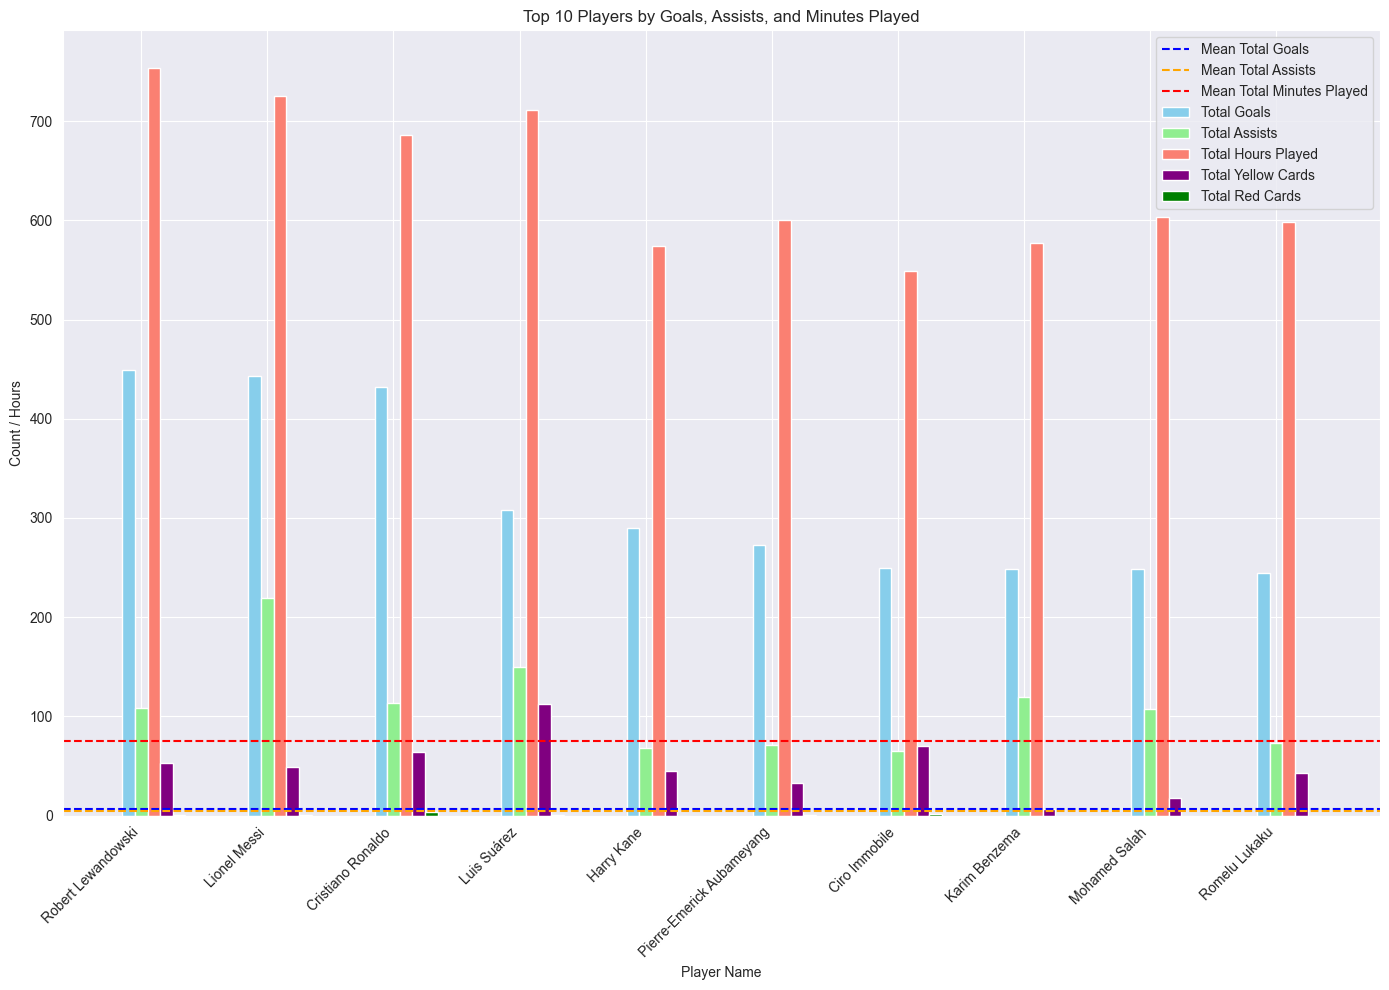

,total_goals,total_assists,total_minutes,yellow_cards,red_cards
count,10.000000,10.000000,10.000000,10.000000,10.000000
mean,318.800000,109.500000,637.916667,49.500000,1.000000
std,87.024645,47.476895,73.356046,29.455239,1.247219
min,245.000000,65.000000,549.300000,7.000000,0.000000
25%,249.250000,71.500000,582.616667,35.500000,0.000000
50%,281.500000,107.500000,601.941667,47.000000,1.000000
75%,401.000000,118.500000,704.495833,61.250000,1.000000
max,449.000000,219.000000,753.666667,113.000000,4.000000


In [5]:
# Summing goals, assists, and minutes played for each player
performance = df.groupby('player_name').agg(
    total_goals=('goals', 'sum'),
    total_assists=('assists', 'sum'),
    total_minutes=('minutes_played', 'sum'),
    yellow_cards=('yellow_cards', 'sum'),
    red_cards=('red_cards', 'sum')
).reset_index()

performance['total_minutes'] = performance['total_minutes'] / 60  # Convert minutes to hours

# Get the top 10 players by total goals
top_performers = performance.sort_values(by='total_goals', ascending=False).head(10)

# Calculate mean values
mean_goals = performance['total_goals'].mean()
mean_assists = performance['total_assists'].mean()
mean_minutes = performance['total_minutes'].mean()

# Set the positions and width for the bars
bar_width = 0.10
positions = np.arange(len(top_performers['player_name']))

# Create the figure and axis
fig, ax = plt.subplots(figsize=(14, 10))

# Plot for Total Goals
ax.bar(positions, top_performers['total_goals'], width=bar_width, label='Total Goals', color='skyblue')

# Plot for Total Assists
ax.bar(positions + bar_width, top_performers['total_assists'], width=bar_width, label='Total Assists', color='lightgreen')

# Plot for Total Minutes Played
ax.bar(positions + 2 * bar_width, top_performers['total_minutes'], width=bar_width, label='Total Hours Played', color='salmon')

# Plot for Yellow Cards
ax.bar(positions + 3 * bar_width, top_performers['yellow_cards'], width=bar_width, label='Total Yellow Cards', color='purple')

# Plot for Red Cards
ax.bar(positions + 4 * bar_width, top_performers['red_cards'], width=bar_width, label='Total Red Cards', color='green')

# Set the x-axis ticks and labels
ax.set_xticks(positions + bar_width)
ax.set_xticklabels(top_performers['player_name'], rotation=45, ha='right')

# Add titles and labels
ax.set_title('Top 10 Players by Goals, Assists, and Minutes Played')
ax.set_xlabel('Player Name')
ax.set_ylabel('Count / Hours')
ax.legend()

# Add mean values as horizontal lines
ax.axhline(mean_goals, color='blue', linestyle='--', label='Mean Total Goals')
ax.axhline(mean_assists, color='orange', linestyle='--', label='Mean Total Assists')
ax.axhline(mean_minutes, color='red', linestyle='--', label='Mean Total Minutes Played')

# Show the mean values in the legend
ax.legend()

# Adjust layout for better spacing
plt.tight_layout()

# Show the plot
plt.show()
top_performers.describe()

### Top 10 Players by Goals, Assists, Minutes Played, and Card Statistics

This bar chart visualizes the performance metrics of the top 10 players based on total goals scored. The metrics displayed include:

- **Total Goals**: The number of goals scored by each player.
- **Total Assists**: The number of assists made by each player.
- **Total Minutes Played**: The total number of hours played by each player, converted from minutes.
- **Total Yellow Cards**: The number of yellow cards received by each player, indicating disciplinary actions taken during matches.
- **Total Red Cards**: The number of red cards received

#### Mean Values
- The blue dashed line represents the mean number of goals scored by players across the dataset.
- The orange dashed line indicates the mean number of assists made by players.
- The red dashed line shows the mean number of minutes played by players, also converted to hours.

#### Interpretation
The chart allows for a quick comparison between the top performers and the average performance of all players. Key insights include:

- **Offensive Contribution**: Players exceeding the mean values in goals or assists demonstrate exceptional offensive contributions. These players might be critical for their team's success.
- **Consistent Participation**: Players with higher minutes played indicate consistent participation in matches, suggesting they are trusted by their managers.
- **Disciplinary Records**: The number of yellow and red cards can indicate a player's on-field behavior. A high number of yellow or red cards may suggest aggressive play style or a lack of discipline, potentially leading to negative impacts on the team (e.g., missing matches due to suspensions).

#### Insights
- Players who score high in goals and assists but have low yellow and red cards demonstrate a balance of skill and discipline, making them valuable assets.
- Players with high minutes but lower goal/assist contributions may indicate they play more defensive roles or are part of the team's midfield structure.
- Disciplinary trends (high yellow/red cards) can be used by teams to work on strategies to improve player behavior and reduce suspensions.

The fact that the mean of red cards for the top 10 is 1.0 justify the low column of red cards in the chart. 

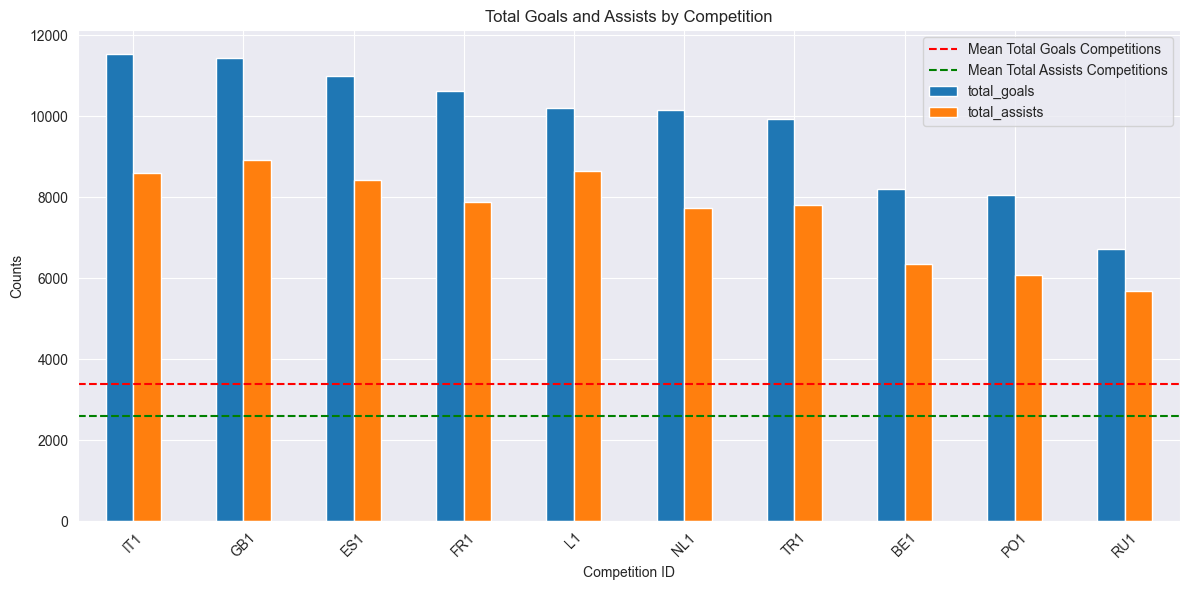

In [6]:
# Summing goals and assists by competition
competition_performance = df.groupby('competition_id').agg(
    total_goals=('goals', 'sum'),
    total_assists=('assists', 'sum')
).reset_index()

#sorting the values of the competition performance and select the top 10
competition_performance = competition_performance.sort_values(by='total_goals', ascending=False)
competition_performance_top = competition_performance.head(10)

# Plotting competition performance
competition_performance_top.set_index('competition_id').plot(kind='bar', figsize=(12, 6))
plt.title('Total Goals and Assists by Competition')
plt.ylabel('Counts')
plt.xlabel('Competition ID')
plt.xticks(rotation=45)
plt.grid(True)

mean_goals_competition = competition_performance['total_goals'].mean()
plt.axhline(mean_goals_competition, color='red', linestyle='--', label='Mean Total Goals Competitions')

mean_assists_competition = competition_performance['total_assists'].mean()
plt.axhline(mean_assists_competition, color='green', linestyle='--', label='Mean Total Assists Competitions')


plt.legend()
plt.tight_layout()
plt.show()


## Total Goals and Assists by Competition
This bar chart visualizes the total number of **goals** and **assists** across the top 10 competitions, based on total goals scored.

- Total Goals: The number of goals scored by all players in each competition.
- Total Assists: The number of assists made by all players in each competition.
- The data is sorted by total goals, showing the competitions with the highest goal counts.

### Plot Explanation:
- X-Axis: Represents the competition_id. These are the unique identifiers for the competitions in which players participated.
- Y-Axis: Displays the total goals and assists for each competition.

The competition with most goals and assists is the one with the competition_id IT1 which is the Italian Serie A. The competition with the least goals and assists in the top 10 is the one with the competition_id RU1 which is the Russian Premier League.

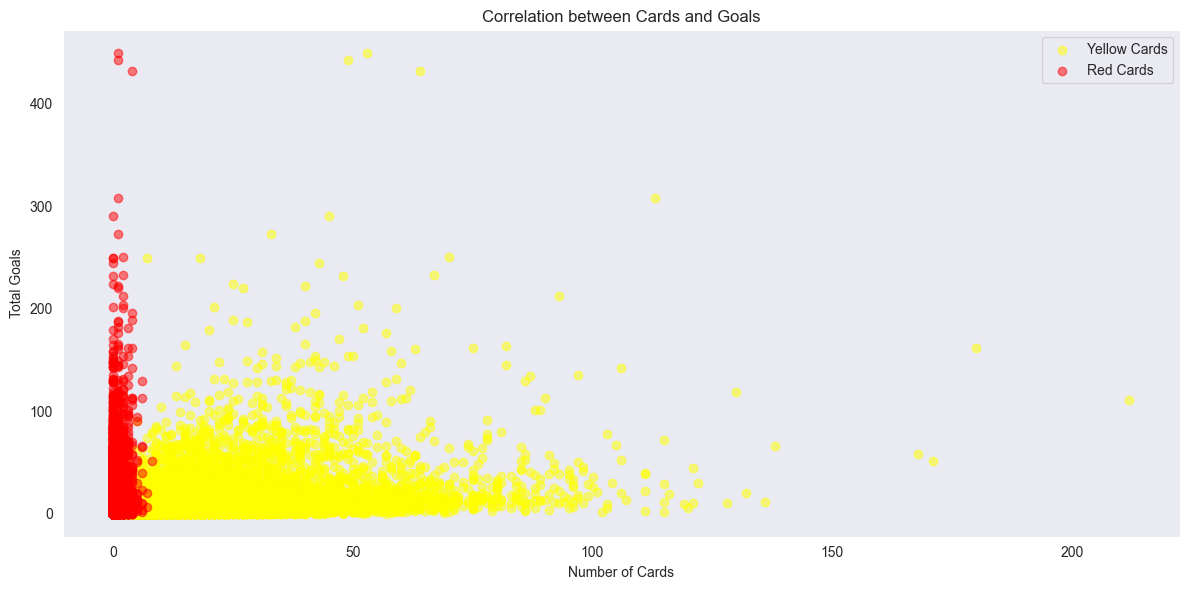

In [7]:
# Calculating total cards and performance metrics
performance_with_cards = df.groupby('player_name').agg(
    total_yellow_cards=('yellow_cards', 'sum'),
    total_red_cards=('red_cards', 'sum'),
    total_goals=('goals', 'sum'),
    total_assists=('assists', 'sum')
).reset_index()

# Plotting correlation between cards and performance
plt.figure(figsize=(12, 6))
plt.scatter(performance_with_cards['total_yellow_cards'], performance_with_cards['total_goals'], alpha=0.5, label='Yellow Cards', color='yellow')
plt.scatter(performance_with_cards['total_red_cards'], performance_with_cards['total_goals'], alpha=0.5, label='Red Cards', color='red')
plt.title('Correlation between Cards and Goals')
plt.xlabel('Number of Cards')
plt.ylabel('Total Goals')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()


## Correlation between Cards and Goals
This scatter plot visualizes the correlation between the number of cards (yellow and red) and the total number of goals scored by players.

### Explanation of the Plot:
- Yellow Dots: Represent the correlation between yellow cards and the total number of goals.
- Red Dots: Show the correlation between red cards and the total number of goals.

### Insights:
The data shows that most players with a low number of cards (yellow or red) tend to have a wide range of goal totals, with the majority clustering under 100 goals.
Few players have accumulated a significant number of red cards, and these players generally have lower goal counts.

### Interpretation:
While there doesn't appear to be a strong positive correlation between the number of yellow or red cards and goals, the plot suggests that accumulating many cards (especially red) is often associated with lower goal totals.

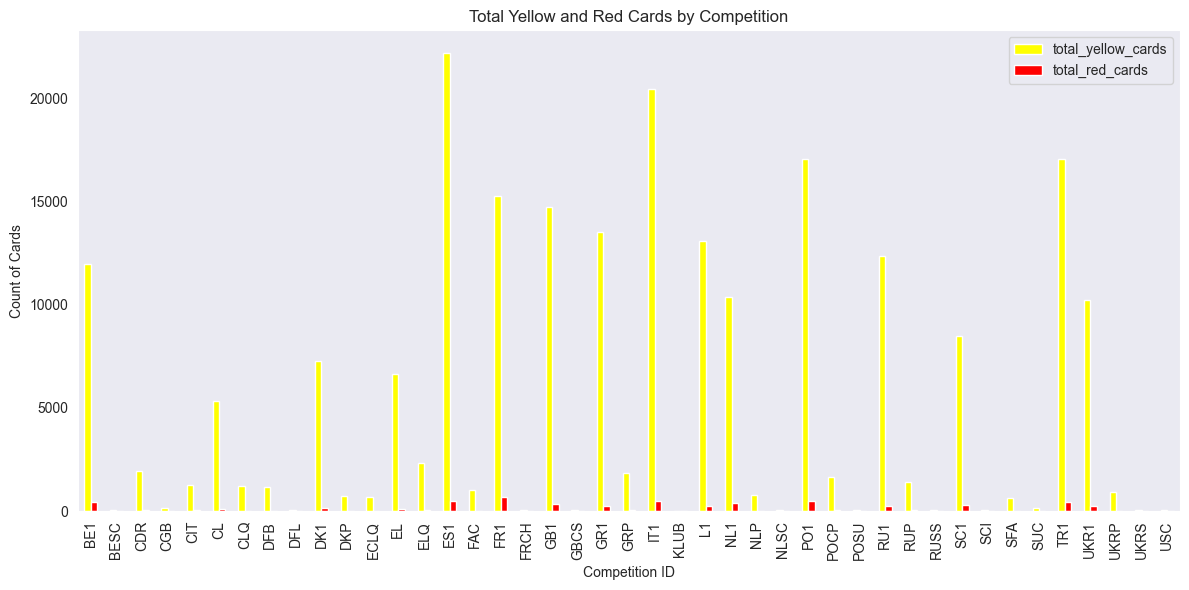

In [8]:
# Summing cards by competition
cards_by_competition = df.groupby('competition_id').agg(
    total_yellow_cards=('yellow_cards', 'sum'),
    total_red_cards=('red_cards', 'sum')
).reset_index()

# Plotting cards by competition
cards_by_competition.set_index('competition_id').plot(kind='bar', figsize=(12, 6), color=['yellow', 'red'])
plt.title('Total Yellow and Red Cards by Competition')
plt.ylabel('Count of Cards')
plt.xlabel('Competition ID')
plt.xticks(rotation=90)
plt.grid()
plt.tight_layout()
plt.show()


## Total Yellow and Red Cards by Competition
This bar chart visualizes the total number of **yellow** and **red** cards across different competitions.

###  Insights:
- The competition with the most yellow cards is the one with the competition_id ES1, which is the Spanish La Liga, it's also as a lower number of red cards.
- The competition with the most red cards is the one with the competition_id FR1, which is the French League 1. 
- The competitions with the least yellow and red cards is the one with the competition_id:
    - BESC: Belgian Pro League Supercup,
    - DFL: German DFL Supercup,
    - FRCH: French Trophée des Champions,
    - GBCS: England Comunity Shield, 
    - KLUB: FIFA Club World Cup, 
    - NLSC: Netherlands Johan Cruijff Schaal,
    - POSU: Portugal Supertaça Cândido de Oliveira,
    - RUSS: Russian Super Cup,
    - SCI: Supercoppa Italiana,
    - UKRS: Ukrainian Super Cup,
    - USC: UEFA Super Cup.

### Interpretation:
The number of cards (yellow and red) can indicate the level of physicality or aggression in a competition, as well as the overall discipline of players. Competitions with higher card counts may have more intense matches, leading to more fouls and disciplinary actions.

In [9]:
df.to_csv('../cleaned_csv/appearances_cleaned.csv', index=False)